# Assignment 4: CNN Image Binarization & Weight Initialization Dynamics
**Author:** Kristian Hudák  
**Course:** AI Olympiad (OAI) Preparation Course

This project investigates single-layer Convolutional Neural Networks (1x1 Conv2D) for image binarization and threshold learning:
- **Part 1:** Analytical manual weight design ($W=10.0, b=-5.0$) combined with Sigmoid activation to simulate Heaviside step-function thresholding.
- **Part 2:** Empirical learning from scratch: initializing weights to zero and optimizing parameters using `BCELoss` and `Adam` optimizer to autonomously discover the optimal binarization boundary.

---
## Part 1: Analytical Minimal Network Design with Hardcoded Weights


In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np


In [32]:
!wget https://www.agentspace.org/download/panda.zip
!unzip panda.zip

--2025-11-11 22:22:50--  https://www.agentspace.org/download/panda.zip
Resolving www.agentspace.org (www.agentspace.org)... 62.168.101.9
Connecting to www.agentspace.org (www.agentspace.org)|62.168.101.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 149062 (146K) [application/zip]
Saving to: ‘panda.zip.2’

panda.zip.2         100%[===================>] 145.57K   295KB/s    in 0.5s    

2025-11-11 22:22:52 (295 KB/s) - ‘panda.zip.2’ saved [149062/149062]

Archive:  panda.zip
replace panda/caltech-101.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [33]:
from torchvision import datasets, transforms
from PIL import Image
import os
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),  # convert RGB to 1-channel grayscale
    transforms.ToTensor()
])  # converts PIL image to Tensor in [0,1]
image_dir = "./panda"  # path to the directory with images
images = []
for fname in os.listdir(image_dir):
    if fname.lower().endswith((".png", ".jpg", ".jpeg")):  # only image files
        path = os.path.join(image_dir, fname)
        img = Image.open(path).convert("RGB")  # ensure 3 channels
        img_tensor = transform(img)
        images.append(img_tensor)

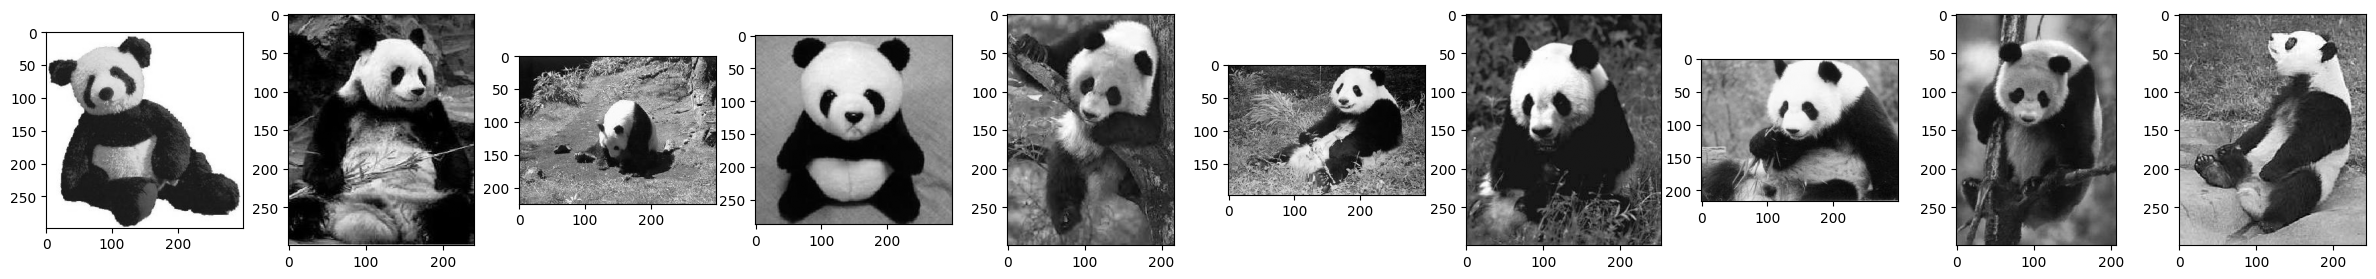

In [34]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(images), figsize=(30, 3))
for i in range(len(images)):
    axes[i].imshow(images[i].permute(1,2,0), cmap='gray')

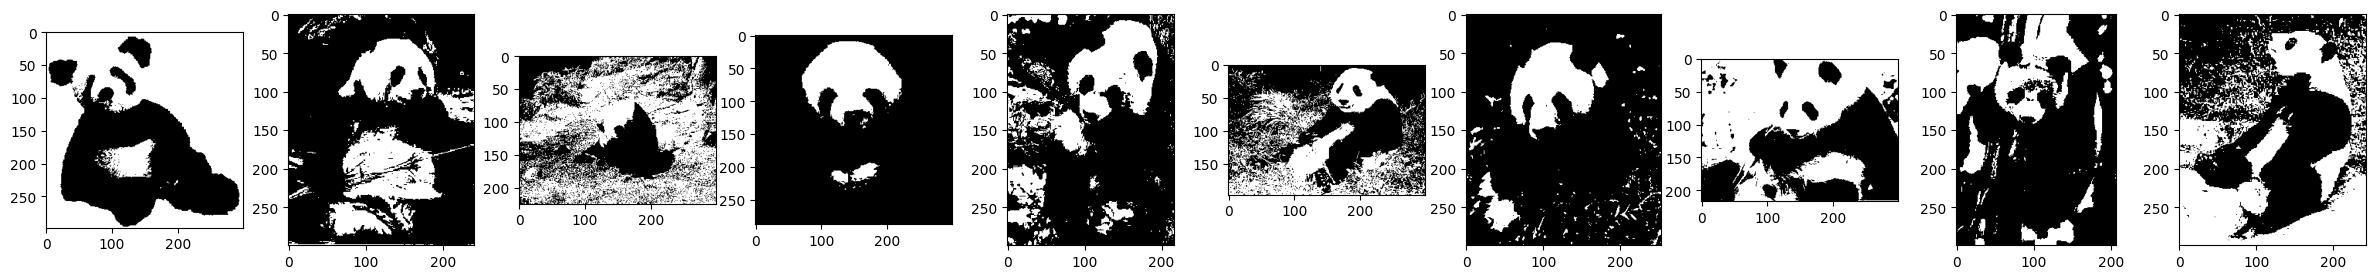

In [35]:
binaries = [image > 0.5 for image in images]
fig, axes = plt.subplots(1, len(binaries), figsize=(30, 3))
for i in range(len(binaries)):
    axes[i].imshow(binaries[i].permute(1,2,0), cmap='gray')

In [36]:
class Binarizacia(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 1, kernel_size=1, bias=True)

    def forward(self,x):
      x = self.conv(x)
      return torch.sigmoid(x)

In [37]:
model = Binarizacia()

In [38]:
with torch.no_grad():
    model.conv.weight.data = torch.tensor([[[[10.0]]]])
    model.conv.bias.data = torch.tensor([-5.0])



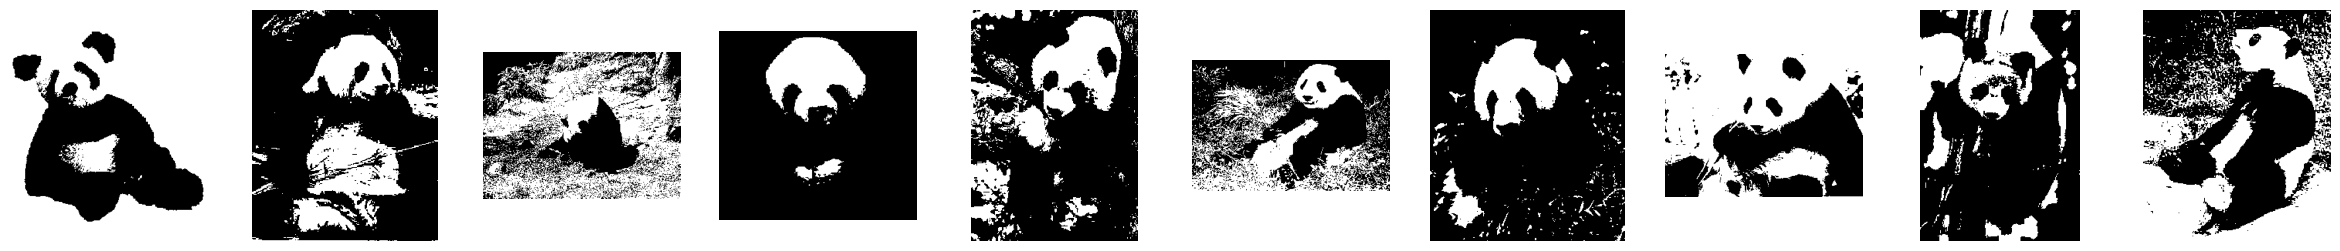

In [39]:
model.eval()
fig, axes = plt.subplots(1, len(images), figsize=(30, 3))
for i, img in enumerate(images):
    with torch.no_grad():
        out = model(img.unsqueeze(0))
        bin_out = (out > 0.5).float().squeeze().numpy()
    axes[i].imshow(bin_out, cmap='gray')
    axes[i].axis('off')
plt.show()

In [40]:
print(output)

tensor([[[[5.8198e-18, 3.2380e-20, 6.7978e-20,  ..., 1.9616e-04,
           2.4602e-01, 2.4768e-07],
          [6.7978e-20, 6.7978e-20, 2.9960e-19,  ..., 8.6373e-01,
           9.9991e-01, 7.9377e-03],
          [1.6669e-21, 6.7978e-20, 1.3205e-18,  ..., 9.9980e-01,
           1.0000e+00, 9.6544e-01],
          ...,
          [1.0000e+00, 1.0000e+00, 1.0000e+00,  ..., 1.0000e+00,
           1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00, 1.0000e+00,  ..., 1.0000e+00,
           1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00, 1.0000e+00,  ..., 1.0000e+00,
           1.0000e+00, 1.0000e+00]]]], grad_fn=<SigmoidBackward0>)


In [41]:
for param in model.parameters():
    print(param.data)

tensor([[[[10.]]]])
tensor([-5.])


---
## Part 2: Autonomous Learning from Zero-Initialized Parameters

In this section, weights and bias are initialized strictly to zero. The network trains via backpropagation with Binary Cross-Entropy Loss to autonomously learn the optimal decision boundary.


In [42]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np


In [43]:
!wget https://www.agentspace.org/download/panda.zip
!unzip panda.zip

--2025-11-11 22:23:43--  https://www.agentspace.org/download/panda.zip
Resolving www.agentspace.org (www.agentspace.org)... 62.168.101.9
Connecting to www.agentspace.org (www.agentspace.org)|62.168.101.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 149062 (146K) [application/zip]
Saving to: ‘panda.zip.3’

panda.zip.3         100%[===================>] 145.57K   305KB/s    in 0.5s    

2025-11-11 22:23:45 (305 KB/s) - ‘panda.zip.3’ saved [149062/149062]

Archive:  panda.zip
replace panda/caltech-101.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [44]:
from torchvision import datasets, transforms
from PIL import Image
import os
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),  # convert RGB to 1-channel grayscale
    transforms.ToTensor()
])  # converts PIL image to Tensor in [0,1]
image_dir = "./panda"  # path to the directory with images
images = []
for fname in os.listdir(image_dir):
    if fname.lower().endswith((".png", ".jpg", ".jpeg")):  # only image files
        path = os.path.join(image_dir, fname)
        img = Image.open(path).convert("RGB")  # ensure 3 channels
        img_tensor = transform(img)
        images.append(img_tensor)

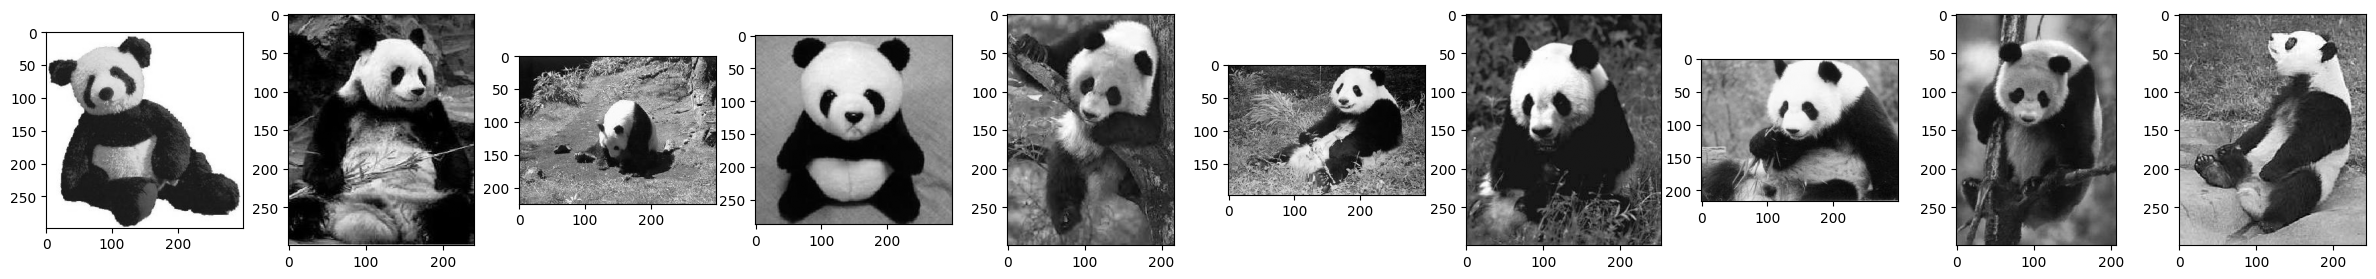

In [45]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(images), figsize=(30, 3))
for i in range(len(images)):
    axes[i].imshow(images[i].permute(1,2,0), cmap='gray')

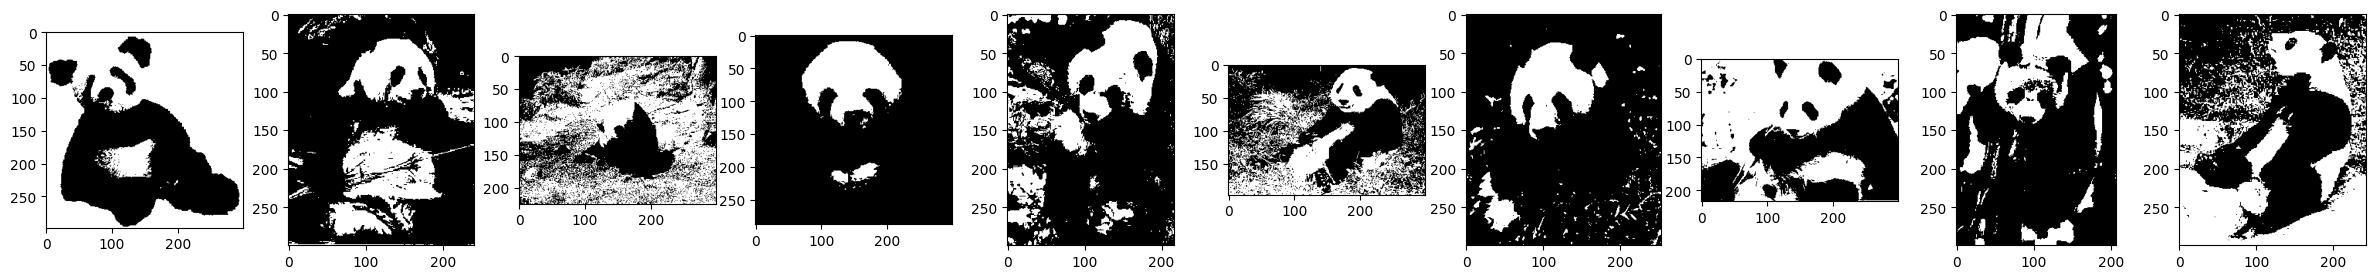

In [46]:
binaries = [image > 0.5 for image in images]
fig, axes = plt.subplots(1, len(binaries), figsize=(30, 3))
for i in range(len(binaries)):
    axes[i].imshow(binaries[i].permute(1,2,0), cmap='gray')

In [47]:
class Binarizacia(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 1, kernel_size=1, bias=True)

    def forward(self,x):
      x = self.conv(x)
      return torch.sigmoid(x)

In [48]:
model = Binarizacia()

In [49]:
with torch.no_grad():
    model.conv.weight.zero_()
    model.conv.bias.zero_()



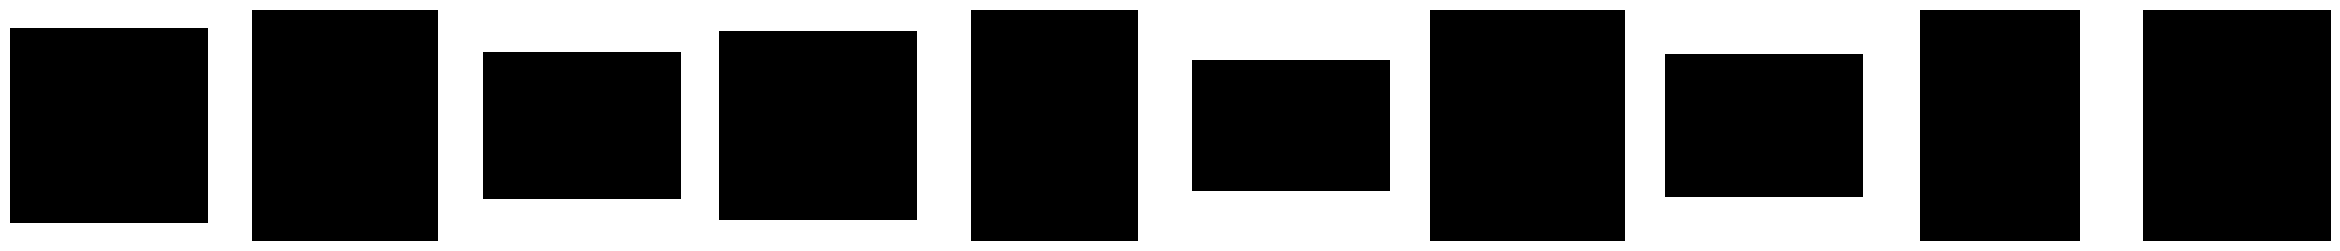

In [50]:
fig, axes = plt.subplots(1, len(images), figsize=(30, 3))
model.eval()
for i, img in enumerate(images):
    with torch.no_grad():
        out = model(img.unsqueeze(0))
        bin_out = (out > 0.5).float().squeeze().numpy()
    axes[i].imshow(bin_out, cmap='gray')
    axes[i].axis('off')
plt.show()

In [51]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.1)

In [52]:
for epoch in range(1500):
    total_loss = 0
    for img, target in zip(images, binaries):
        img, target = img.unsqueeze(0), target.unsqueeze(0)
        optimizer.zero_grad()
        output = model(img)
        loss = criterion(output, target.float())
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1:02d} | Loss: {total_loss:.4f}")

Epoch 01 | Loss: 6.7290
Epoch 02 | Loss: 5.8581
Epoch 03 | Loss: 5.2839
Epoch 04 | Loss: 4.7833
Epoch 05 | Loss: 4.3674
Epoch 06 | Loss: 4.0230
Epoch 07 | Loss: 3.7381
Epoch 08 | Loss: 3.5001
Epoch 09 | Loss: 3.2982
Epoch 10 | Loss: 3.1250
Epoch 11 | Loss: 2.9751
Epoch 12 | Loss: 2.8442
Epoch 13 | Loss: 2.7287
Epoch 14 | Loss: 2.6259
Epoch 15 | Loss: 2.5338
Epoch 16 | Loss: 2.4507
Epoch 17 | Loss: 2.3752
Epoch 18 | Loss: 2.3063
Epoch 19 | Loss: 2.2431
Epoch 20 | Loss: 2.1848
Epoch 21 | Loss: 2.1309
Epoch 22 | Loss: 2.0807
Epoch 23 | Loss: 2.0340
Epoch 24 | Loss: 1.9903
Epoch 25 | Loss: 1.9492
Epoch 26 | Loss: 1.9107
Epoch 27 | Loss: 1.8743
Epoch 28 | Loss: 1.8399
Epoch 29 | Loss: 1.8073
Epoch 30 | Loss: 1.7764
Epoch 31 | Loss: 1.7470
Epoch 32 | Loss: 1.7190
Epoch 33 | Loss: 1.6923
Epoch 34 | Loss: 1.6667
Epoch 35 | Loss: 1.6423
Epoch 36 | Loss: 1.6189
Epoch 37 | Loss: 1.5964
Epoch 38 | Loss: 1.5748
Epoch 39 | Loss: 1.5541
Epoch 40 | Loss: 1.5341
Epoch 41 | Loss: 1.5148
Epoch 42 | Loss:

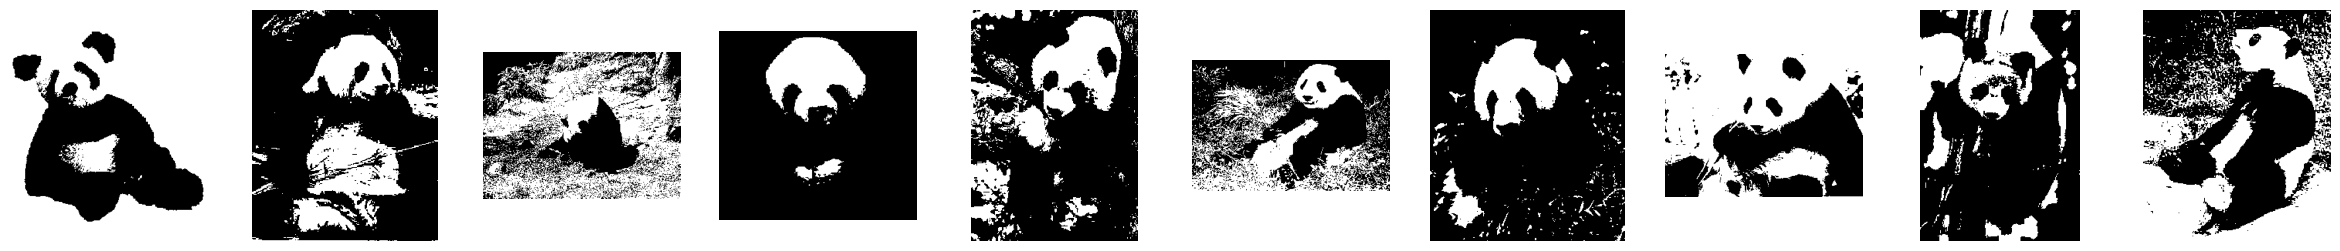

In [53]:
model.eval()
fig, axes = plt.subplots(1, len(images), figsize=(30, 3))
for i, img in enumerate(images):
    with torch.no_grad():
        out = model(img.unsqueeze(0))
        bin_out = (out > 0.5).float().squeeze().numpy()
    axes[i].imshow(bin_out, cmap='gray')
    axes[i].axis('off')
plt.show()

In [54]:
print(output)

tensor([[[[5.8198e-18, 3.2380e-20, 6.7978e-20,  ..., 1.9616e-04,
           2.4602e-01, 2.4768e-07],
          [6.7978e-20, 6.7978e-20, 2.9960e-19,  ..., 8.6373e-01,
           9.9991e-01, 7.9377e-03],
          [1.6669e-21, 6.7978e-20, 1.3205e-18,  ..., 9.9980e-01,
           1.0000e+00, 9.6544e-01],
          ...,
          [1.0000e+00, 1.0000e+00, 1.0000e+00,  ..., 1.0000e+00,
           1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00, 1.0000e+00,  ..., 1.0000e+00,
           1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00, 1.0000e+00,  ..., 1.0000e+00,
           1.0000e+00, 1.0000e+00]]]], grad_fn=<SigmoidBackward0>)


In [55]:
for param in model.parameters():
    print(param.data)

tensor([[[[189.1258]]]])
tensor([-94.5813])
